This is an adaption to the code repo: https://github.com/spmallick/learnopencv/tree/master/Image-Captioning-using-ResNet-and-LSTM<br>bolg: https://learnopencv.com/image-captioning/<br>




Specifically, adaptions made listed below:
- replace dataset with ..., and change the way it processes the dataset accordingly
- adjust lr and add dropout to decoder to fix overfitting

In [ ]:
import os
import re
import csv
import pickle
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from torchvision import transforms
from datasets import load_dataset
import torchvision.models as models
from torchvision.models import ResNet50_Weights
from collections import Counter
from PIL import Image
import numpy as np
import random

from tqdm import tqdm

In [ ]:
EMBED_DIM = 256
HIDDEN_DIM = 512
# lower the lr
LEARNING_RATE = 0.0001
BATCH_SIZE = 8
EPOCHS = 25
MIN_WORD_FREQ = 1 # for what?
SEED = 42
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 4

""" below params need to be rechecked """
BEST_CHECKPOINT_PATH = "best_checkpoint.pth"  # Checkpoint w/ epoch, model, optimizer, best_val_loss
FINAL_MODEL_PATH = "final_model.pth"          # Final model weights only (saved at the end)
VOCAB_PATH = "vocab.pkl"                      # Where we save the vocabulary

# Set this to True if you want to resume from the best checkpoint
RESUME = False

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [ ]:
class Vocabulary:
  def __init__(self, freq_threshold=5):
    self.freq_threshold = freq_threshold
    # self.itos = {0: "<pad>", 1: "<start>", 2: "<end>", 3: "<unk>"}
    self.itos = {0: "pad", 1: "startofseq", 2: "endofseq", 3: "unk"}
    self.stoi = {v: k for k, v in self.itos.items()}
    self.index = 4

  def __len__(self):
    return len(self.itos)

  def tokenizer(self, text):
    text = text.lower()
    """ split the sentence into words """
    """ note that if you use \w, it'll split it into characters """
    tokens = re.findall(r"\w+", text)
    return tokens

  def build_vocabulary(self, sentence_list):
    frequencies = Counter()
    for sentence in sentence_list:
      tokens = self.tokenizer(sentence)
      frequencies.update(tokens)

    for word, freq in frequencies.items():
      if freq >= self.freq_threshold:
        """ previously index set to 4 because we have 4 predefined tokens(in the initial itos) """
        self.stoi[word] = self.index
        self.itos[self.index] = word
        self.index += 1

  """ allow for netural network to process """
  def numericalize(self, text):
    tokens = self.tokenizer(text)
    numericalized = []
    for token in tokens:
      if token in self.stoi:
        numericalized.append(self.stoi[token])
      else:
        numericalized.append(self.stoi["<unk>"])
    return numericalized


<>:15: SyntaxWarning: invalid escape sequence '\w'
<>:15: SyntaxWarning: invalid escape sequence '\w'
/tmp/ipython-input-119331113.py:15: SyntaxWarning: invalid escape sequence '\w'
  """ note that if you use \w, it'll split it into characters """


In [ ]:
image_size = 256
batch_size = 4
train_transform = transforms.Compose([transforms.Resize((image_size, image_size)),
  transforms.RandomHorizontalFlip(),
  transforms.ToTensor(),
  transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])])
dataset = load_dataset("jugg1024/pokemon-gpt4o-captions", split="train")
dataset

Dataset({
    features: ['image', 'en_text', 'zh_text'],
    num_rows: 833
})

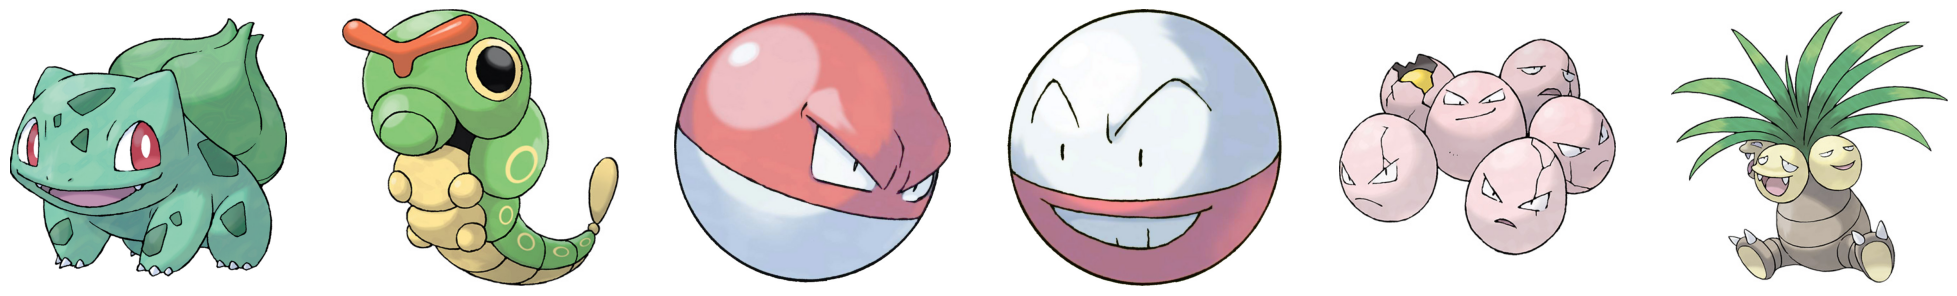

In [ ]:
# @title
def plot_images(images):
  plt.figure(figsize=(25,25))
  for i in range(len(images)):
    ax = plt.subplot(1, len(images), i+1)
    plt.imshow(images[i])
    plt.axis("off")

plot_images([np.array(dataset["image"][i]) for i in range(6)])

In [ ]:
vocab = Vocabulary(freq_threshold=MIN_WORD_FREQ)
vocab.build_vocabulary(dataset["en_text"])

def preprocess(data):
  data["image"] = train_transform(data["image"])
  numercial_cap = [vocab.stoi["startofseq"]]
  numercial_cap += (vocab.numericalize(data["en_text"]))
  numercial_cap.append(vocab.stoi["endofseq"])
  data["caption"] = numercial_cap
  # data["caption"] = vocab.stoi["startofseq"] + data['en_text'] + vocab.stoi["endofseq"]
  return data

dataset = dataset.map(preprocess, remove_columns=["en_text", "zh_text"])
# dataset['test'] = dataset['test'].map(preprocess, remove_columns=["en_text", "zh_text"])
dataset.set_format("torch", columns=["image", "caption"])
dataset

Map:   0%|          | 0/833 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'caption'],
    num_rows: 833
})

In [ ]:
dataset = dataset.train_test_split(test_size=0.2, seed=SEED)
dataset

DatasetDict({
    train: Dataset({
        features: ['image', 'caption'],
        num_rows: 666
    })
    test: Dataset({
        features: ['image', 'caption'],
        num_rows: 167
    })
})

In [ ]:
vocab_size = len(vocab)
vocab_size

4659

In [ ]:
import torchvision
def collate_fn(batch):
  batch.sort(key=lambda x: len(x["caption"]), reverse=True)
  images = [item["image"] for item in batch]
  captions = [item["caption"] for item in batch]
  lengths = [len(cap) for cap in captions]
  max_len = max(lengths)

  padded_captions = torch.zeros(len(captions), max_len, dtype=torch.long)
  for i, cap in enumerate(captions):
    end = lengths[i]
    padded_captions[i, :end] = cap[:end]

  images = torch.stack(images, dim=0)
  return images, padded_captions, lengths

train_dataset = dataset['train']
val_dataset = dataset['test']
train_dataloader = torch.utils.data.DataLoader(
    train_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn, shuffle=True
)

val_dataloader = torch.utils.data.DataLoader(
    val_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn, shuffle=True
)

In [ ]:
batch = next(iter(train_dataloader))
images, captions, _ = batch
for image, caption in zip(images, captions):
  print(image.shape)
  print(caption.shape)

torch.Size([3, 256, 256])
torch.Size([134])
torch.Size([3, 256, 256])
torch.Size([134])
torch.Size([3, 256, 256])
torch.Size([134])
torch.Size([3, 256, 256])
torch.Size([134])
torch.Size([3, 256, 256])
torch.Size([134])
torch.Size([3, 256, 256])
torch.Size([134])
torch.Size([3, 256, 256])
torch.Size([134])
torch.Size([3, 256, 256])
torch.Size([134])


ResNet as Encoder<br>LSTM as Decoder

In [ ]:
class ResNetEncoder(nn.Module):
  def __init__(self, embed_dim):
    super().__init__()
    resnet = models.resnet50(weights=ResNet50_Weights.DEFAULT)
    for param in resnet.parameters():
      param.requires_grad = False
    """ move off the last layer: FC (2048 -> 1000) """
    modules = list(resnet.children())[:-1]
    self.resnet = nn.Sequential(*modules)

    self.fc = nn.Linear(resnet.fc.in_features, embed_dim)
    self.batch_norm = nn.BatchNorm1d(embed_dim, momentum=0.01)

  def forward(self, images):
    """ train only newly defined layers, freeze the pretrained layers """
    # with torch.no_grad():
    #   # (bz, 2048, 1, 1)
    features = self.resnet(images)
    # (bz, 2048, 1, 1) -> (bz, 2048)
    features = features.view(features.size(0), -1) # '-1' implies to calculate the other dimension automatically
    features = self.fc(features)
    features = self.batch_norm(features)
    return features

class LSTMDecoder(nn.Module):
  def __init__(self, embed_dim, hidden_dim, vocab_size, num_layers=1):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embed_dim)
    # to fix overfitting
    self.dropout = nn.Dropout(0.2)
    self.lstm = nn.LSTM(embed_dim, hidden_dim, num_layers, batch_first=True)
    self.fc = nn.Linear(hidden_dim, vocab_size)

  def forward(self, features, caption):
    caption = caption[:, :-1]
    emb = self.embedding(caption)
    emb = self.dropout(emb)
    features = features.unsqueeze(1)
    lstm_input = torch.cat((features, emb), dim=1)
    outputs, _ = self.lstm(lstm_input)
    logits = self.fc(outputs)
    return logits



class ImageCaptioningModel(nn.Module):
  def __init__(self, encoder, decoder):
    super().__init__()
    self.encoder = encoder
    self.decoder = decoder

  def forward(self, images, captions):
    features = self.encoder(images)
    outputs = self.decoder(features, captions)
    return outputs


In [ ]:
def train_by_epoch(model, dataloader, criterion, optimizer, vocab_size, epoch):
  model.train()
  total_loss = 0
  progress_bar = tqdm(dataloader, desc=f"Epoch {epoch + 1}", unit="batch")
  for images, captions, _lengths in progress_bar:
    images = images.to(device)
    captions = captions.to(device)

    optimizer.zero_grad()
    # (bz, seq_len, vocab_size)
    outputs = model(images, captions)
    outputs = outputs[:, 1:, :].contiguous().view(-1, vocab_size)
    targets = captions[:, 1:].contiguous().view(-1)

    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    total_loss += loss.item()
    progress_bar.set_postfix({"loss": f"{loss.item():.4f}"})
  avg_loss = total_loss / len(dataloader)
  return avg_loss

def validate(model, dataloader, criterion, vocab_size):
  model.eval()
  total_loss = 0
  with torch.no_grad():
    for images, captions, _lengths in dataloader:
      images = images.to(device)
      captions = captions.to(device)
      outputs = model(images, captions)
      outputs = outputs[:, 1:, :].contiguous().view(-1, vocab_size)
      targets = captions[:, 1:].contiguous().view(-1)

      # outputs = outputs.contiguous().view(-1, vocab_size)
      # targets = captions.contiguous().view(-1)
      loss = criterion(outputs, targets)
      total_loss += loss.item()
    avg_val_loss = total_loss / len(dataloader)
    return avg_val_loss

In [ ]:
encoder = ResNetEncoder(EMBED_DIM)
decoder = LSTMDecoder(EMBED_DIM, HIDDEN_DIM, 4096)
# decoder = LSTMDecoder(EMBED_DIM, HIDDEN_DIM, vocab_size)
model = ImageCaptioningModel(encoder, decoder).to(device)

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print(f"{total_params:,} total parameters.")
total_trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad)
print(f"{total_trainable_params:,} training parameters.")

28,759,872 total parameters.
5,251,840 training parameters.


In [ ]:
criterion = nn.CrossEntropyLoss(ignore_index=vocab.stoi["pad"])
parameters = (
  list(model.decoder.parameters()) + list(model.encoder.fc.parameters())
  + list(model.encoder.batch_norm.parameters()) )
optimizer = optim.AdamW(parameters, lr=LEARNING_RATE)

start_epoch = 0
best_val_loss = float("inf")

In [ ]:
try:
    for epoch in range(start_epoch, EPOCHS):
        train_loss = train_by_epoch(model, train_dataloader, criterion, optimizer, vocab_size, epoch)
        val_loss = validate(model, val_dataloader, criterion, vocab_size)

        print(f"[Epoch {epoch+1}/{EPOCHS}] Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

        # Save checkpoint if it's the best so far
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            checkpoint_dict = {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss
            }
            torch.save(checkpoint_dict, BEST_CHECKPOINT_PATH)
            print(f"New best model saved -> {BEST_CHECKPOINT_PATH} (val_loss={val_loss:.4f})")

        final_checkpoint_dict = {
                "model_state_dict": model.state_dict(),
            }
        torch.save(final_checkpoint_dict, FINAL_MODEL_PATH)

except KeyboardInterrupt:
    print("\nTraining interrupted by user. Best checkpoint is already saved if it improved during training.")

print(f"\nFinal model weights saved to {FINAL_MODEL_PATH}")
print(f"Best val_loss={best_val_loss:.4f} (checkpoint at {BEST_CHECKPOINT_PATH})")

Epoch 1: 100%|██████████| 84/84 [00:12<00:00,  6.64batch/s, loss=6.3768]


[Epoch 1/25] Train Loss: 7.1890 | Val Loss: 5.4098
New best model saved -> best_checkpoint.pth (val_loss=5.4098)


Epoch 2: 100%|██████████| 84/84 [00:12<00:00,  6.56batch/s, loss=5.4670]


[Epoch 2/25] Train Loss: 5.0554 | Val Loss: 4.9844
New best model saved -> best_checkpoint.pth (val_loss=4.9844)


Epoch 3: 100%|██████████| 84/84 [00:12<00:00,  6.72batch/s, loss=5.0262]


...

[Epoch 23/25] Train Loss: 3.2099 | Val Loss: 3.6170
New best model saved -> best_checkpoint.pth (val_loss=3.6170)


Epoch 24: 100%|██████████| 84/84 [00:12<00:00,  6.55batch/s, loss=3.0623]


[Epoch 24/25] Train Loss: 3.2014 | Val Loss: 3.5822
New best model saved -> best_checkpoint.pth (val_loss=3.5822)


Epoch 25: 100%|██████████| 84/84 [00:13<00:00,  6.44batch/s, loss=3.5259]


[Epoch 25/25] Train Loss: 3.1762 | Val Loss: 3.5770
New best model saved -> best_checkpoint.pth (val_loss=3.5770)

Final model weights saved to final_model.pth
Best val_loss=3.5770 (checkpoint at best_checkpoint.pth)
